# Dữ liệu bảng — lựa chọn tập dữ liệu và EDA (30%)

**Học phần:** Nền tảng lập trình cho phân tích và trực quan dữ liệu
**Học kỳ 261, năm học 2026–2027 · Giảng viên:** Lê Thành Sách
**Trường:** Đại học Bách Khoa – ĐHQG-HCM · Khoa Khoa học và Kỹ thuật Máy tính

**Nhóm T&D**

| Thành viên | MSSV |
|---|---|
| Trần Hữu Anh Triết | 2470745 |
| Ngô Minh Đại | 2470722 |

Notebook này chỉ làm bước chọn tập dữ liệu và khoảng 30% EDA: tổng quan, giá trị thiếu, và cân bằng nhãn. Chưa xử lý thiếu, chưa encoding, chưa scaling, chưa chia tập và chưa huấn luyện mô hình.

Chạy **Run all** trên Google Colab. Ô đầu tiên tải CSV công khai từ UCI; không cần API key.


## 1. Mô tả tập dữ liệu

**Bài toán.** Một lần nhập viện nội trú của bệnh nhân đái tháo đường có bị tái nhập viện trong vòng 30 ngày hay không? Nhãn dương là `readmitted == "<30"`. Hai mức còn lại, `>30` và `NO`, là nhãn âm khi làm bài toán nhị phân ở phần sau. Phần EDA này vẫn giữ đủ ba mức để thấy độ mất cân bằng của nhãn gốc.

**Tập dữ liệu.** Diabetes 130-US Hospitals for Years 1999–2008, UCI Machine Learning Repository, dataset 296.

- Trang tập: https://archive.ics.uci.edu/dataset/296/diabetes+130-us+hospitals+for+years+1999-2008
- File dùng trong notebook: https://archive.ics.uci.edu/static/public/296/data.csv
- Điều khoản sử dụng: theo trang tập dữ liệu trên UCI. Notebook chỉ đọc file công khai, không đóng gói lại bản sao.

**Trích dẫn.** Strack, B., DeShazo, J. P., Gennings, C., Olmo, J. L., Ventura, S., Cios, K. J., & Clore, J. N. (2014). *Impact of HbA1c Measurement on Hospital Readmission Rates: Analysis of 70,000 Clinical Database Patient Records.* BioMed Research International, 2014, 781670.

**Phạm vi checkpoint này** gồm ba phần: tổng quan, giá trị thiếu, và phân bố nhãn. Các phần còn lại ghi ở cuối notebook.


In [1]:
from IPython.display import Markdown, display

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_URL = "https://archive.ics.uci.edu/static/public/296/data.csv"

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["font.size"] = 11

# UCI ghi giá trị thiếu bằng dấu "?".
df = pd.read_csv(DATA_URL, na_values="?", low_memory=False)

ID_COLS = ["encounter_id", "patient_nbr"]
TARGET_COL = "readmitted"
NUMERIC_COLS = [
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient",
    "number_diagnoses",
]
MED_COLS = [
    "metformin",
    "repaglinide",
    "nateglinide",
    "chlorpropamide",
    "glimepiride",
    "acetohexamide",
    "glipizide",
    "glyburide",
    "tolbutamide",
    "pioglitazone",
    "rosiglitazone",
    "acarbose",
    "miglitol",
    "troglitazone",
    "tolazamide",
    "examide",
    "citoglipton",
    "insulin",
    "glyburide-metformin",
    "glipizide-metformin",
    "glimepiride-pioglitazone",
    "metformin-rosiglitazone",
    "metformin-pioglitazone",
]

BASE_DESC = {
    "encounter_id": "Mã một lần nhập viện. Không dùng làm đặc trưng.",
    "patient_nbr": "Mã bệnh nhân. Dùng để chia tập sau này, không dùng làm đặc trưng.",
    "race": "Chủng tộc.",
    "gender": "Giới tính.",
    "age": "Nhóm tuổi theo bin 10 năm, dạng categorical.",
    "weight": "Nhóm cân nặng theo bin. Gần như không được ghi.",
    "admission_type_id": "Mã loại nhập viện. Số nguyên nhưng là categorical.",
    "discharge_disposition_id": "Mã hình thức xuất viện. Số nguyên nhưng là categorical.",
    "admission_source_id": "Mã nguồn nhập viện. Số nguyên nhưng là categorical.",
    "time_in_hospital": "Số ngày nằm viện, từ 1 đến 14.",
    "payer_code": "Mã bên chi trả viện phí.",
    "medical_specialty": "Chuyên khoa của bác sĩ phụ trách.",
    "num_lab_procedures": "Số xét nghiệm trong lần nhập viện.",
    "num_procedures": "Số thủ thuật trong lần nhập viện.",
    "num_medications": "Số thuốc được kê.",
    "number_outpatient": "Số lần khám ngoại trú trong năm trước.",
    "number_emergency": "Số lần cấp cứu trong năm trước.",
    "number_inpatient": "Số lần nhập viện trong năm trước.",
    "diag_1": "Mã ICD-9 chẩn đoán chính.",
    "diag_2": "Mã ICD-9 chẩn đoán phụ.",
    "diag_3": "Mã ICD-9 chẩn đoán phụ thêm.",
    "number_diagnoses": "Số chẩn đoán được ghi.",
    "max_glu_serum": "Kết quả glucose huyết thanh: Norm, >200, >300, hoặc không xét nghiệm.",
    "A1Cresult": "Kết quả HbA1c: Norm, >7, >8, hoặc không xét nghiệm.",
    "change": "Có thay đổi thuốc đái tháo đường hay không (Ch/No).",
    "diabetesMed": "Có được kê thuốc đái tháo đường hay không (Yes/No).",
    "readmitted": "Tái nhập viện: <30 ngày, >30 ngày, hoặc NO.",
}


def column_role(name: str) -> str:
    if name in ID_COLS:
        return "Định danh"
    if name == TARGET_COL:
        return "Nhãn"
    if name in NUMERIC_COLS:
        return "Numerical"
    return "Categorical"


def column_desc(name: str) -> str:
    if name in MED_COLS:
        return "Mức dùng thuốc: No, Steady, Up hoặc Down."
    return BASE_DESC[name]


assert set(BASE_DESC) | set(MED_COLS) == set(df.columns)
assert df.shape == (101766, 50), df.shape
print(f"Đã tải {len(df):,} dòng và {df.shape[1]} cột.")


Đã tải 101,766 dòng và 50 cột.


### Đối chiếu ràng buộc dữ liệu bảng

Đề bài yêu cầu ít nhất 2.000 dòng, ít nhất 10 cột, có giá trị thiếu, có cột categorical để encoding, có cột numerical để scaling, và ưu tiên tập khó (mất cân bằng hoặc outlier).


In [2]:
n_rows, n_cols = df.shape
n_missing_cols = int(df.isna().any().sum())
n_categorical = sum(column_role(col) == "Categorical" for col in df.columns)
n_numerical = len(NUMERIC_COLS)
early_rate = float(np.mean(df[TARGET_COL].to_numpy() == "<30"))
emergency_max = int(df["number_emergency"].max())
outpatient_max = int(df["number_outpatient"].max())

checks = pd.DataFrame(
    [
        ("Số mẫu", "≥ 2.000", f"{n_rows:,}", n_rows >= 2000),
        ("Số cột", "≥ 10", f"{n_cols}", n_cols >= 10),
        ("Giá trị thiếu", "Có", f"{n_missing_cols} cột có thiếu", n_missing_cols > 0),
        ("Cột categorical", "Có, để encoding sau", f"{n_categorical} cột", n_categorical > 0),
        ("Cột numerical", "Có, để scaling sau", f"{n_numerical} cột", n_numerical > 0),
        (
            "Độ khó",
            "Ưu tiên mất cân bằng hoặc outlier",
            f"nhãn <30 = {early_rate:.1%}; number_emergency tối đa {emergency_max}; number_outpatient tối đa {outpatient_max}",
            early_rate < 0.30 and emergency_max > 10,
        ),
    ],
    columns=["Ràng buộc", "Yêu cầu", "Tập này", "Đạt"],
)
checks["Đạt"] = checks["Đạt"].map({True: "Có", False: "Không"})
display(checks)

assert (checks["Đạt"] == "Có").all()
print("Tập dữ liệu đạt toàn bộ ràng buộc bắt buộc của dữ liệu bảng.")
print(
    "Hai cột định danh encounter_id và patient_nbr không tính vào đặc trưng. "
    "Phân phối lệch của số lần khám sẽ được xem cùng phần outlier ở cuối notebook."
)


,Ràng buộc,Yêu cầu,Tập này,Đạt
0,Số mẫu,≥ 2.000,"101,766",Có
1,Số cột,≥ 10,50,Có
2,Giá trị thiếu,Có,9 cột có thiếu,Có
3,Cột categorical,"Có, để encoding sau",39 cột,Có
4,Cột numerical,"Có, để scaling sau",8 cột,Có
5,Độ khó,Ưu tiên mất cân bằng hoặc outlier,nhãn <30 = 11.2%; number_emergency tối đa 76; ...,Có


Tập dữ liệu đạt toàn bộ ràng buộc bắt buộc của dữ liệu bảng.
Hai cột định danh encounter_id và patient_nbr không tính vào đặc trưng. Phân phối lệch của số lần khám sẽ được xem cùng phần outlier ở cuối notebook.


## 2. Tổng quan

Mỗi cột được gán một vai trò. `encounter_id` và `patient_nbr` là định danh. Các mã nhập viện, xuất viện và nguồn nhập viện là số nguyên nhưng sẽ được encoding như categorical. Tám cột đếm và số ngày nằm viện là numerical, dành cho scaling sau này.


Kiểu dữ liệu gốc sau khi đọc file:
str      37
int64    13
Name: count, dtype: int64


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO


,Cột,Vai trò,Kiểu gốc,Mô tả,Tỷ lệ thiếu
0,encounter_id,Định danh,int64,Mã một lần nhập viện. Không dùng làm đặc trưng.,0.0%
1,patient_nbr,Định danh,int64,"Mã bệnh nhân. Dùng để chia tập sau này, không dùng làm đặc trưng.",0.0%
2,readmitted,Nhãn,str,"Tái nhập viện: <30 ngày, >30 ngày, hoặc NO.",0.0%
3,num_lab_procedures,Numerical,int64,Số xét nghiệm trong lần nhập viện.,0.0%
4,num_medications,Numerical,int64,Số thuốc được kê.,0.0%
5,num_procedures,Numerical,int64,Số thủ thuật trong lần nhập viện.,0.0%
6,number_diagnoses,Numerical,int64,Số chẩn đoán được ghi.,0.0%
7,number_emergency,Numerical,int64,Số lần cấp cứu trong năm trước.,0.0%
8,number_inpatient,Numerical,int64,Số lần nhập viện trong năm trước.,0.0%
9,number_outpatient,Numerical,int64,Số lần khám ngoại trú trong năm trước.,0.0%


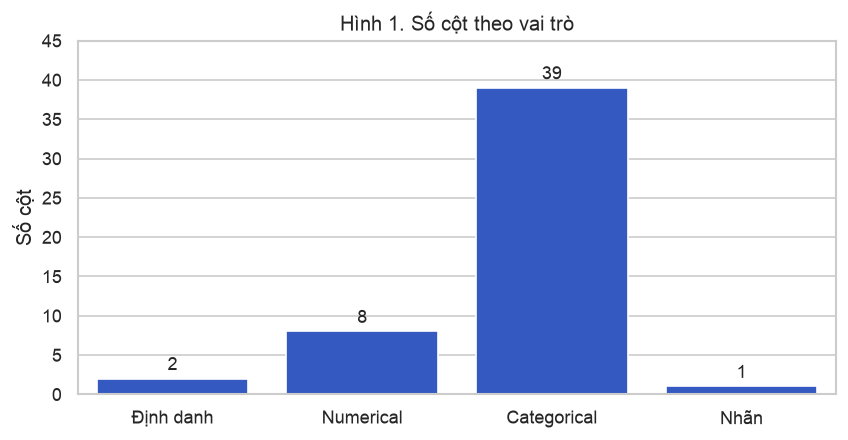

**Kết luận.** Tập có 39 cột categorical để encoding và 8 cột numerical để scaling. Hai cột định danh không đưa vào mô hình; `patient_nbr` chỉ dùng khi chia tập.

In [3]:
schema = pd.DataFrame(
    {
        "Cột": df.columns,
        "Vai trò": [column_role(col) for col in df.columns],
        "Kiểu gốc": [str(df[col].dtype) for col in df.columns],
        "Mô tả": [column_desc(col) for col in df.columns],
        "Tỷ lệ thiếu": [float(df[col].isna().mean()) for col in df.columns],
    }
)
role_order = {"Định danh": 0, "Nhãn": 1, "Numerical": 2, "Categorical": 3}
schema["_role_rank"] = schema["Vai trò"].map(role_order)
schema = schema.sort_values(["_role_rank", "Cột"]).drop(columns="_role_rank").reset_index(drop=True)

print("Kiểu dữ liệu gốc sau khi đọc file:")
print(df.dtypes.value_counts())
display(df.head(3))

shown = schema.copy()
shown["Tỷ lệ thiếu"] = shown["Tỷ lệ thiếu"].map(lambda rate: f"{rate:.1%}")
with pd.option_context("display.max_rows", 60, "display.max_colwidth", 88):
    display(shown)

role_names = ["Định danh", "Numerical", "Categorical", "Nhãn"]
role_counts = np.array([sum(column_role(col) == role for col in df.columns) for role in role_names])

fig, ax = plt.subplots(figsize=(7.2, 3.8))
sns.barplot(x=role_names, y=role_counts, ax=ax, color="#1d4ed8")
for index, count in enumerate(role_counts):
    ax.text(index, count + 0.6, f"{int(count)}", ha="center", va="bottom")
ax.set_ylabel("Số cột")
ax.set_xlabel("")
ax.set_ylim(0, role_counts.max() + 6)
ax.set_title("Hình 1. Số cột theo vai trò")
fig.tight_layout()
plt.show()

display(Markdown(
    f"**Kết luận.** Tập có {int(role_counts[2])} cột categorical để encoding và "
    f"{int(role_counts[1])} cột numerical để scaling. "
    "Hai cột định danh không đưa vào mô hình; `patient_nbr` chỉ dùng khi chia tập."
))


## 3. Giá trị thiếu

Chín cột có giá trị thiếu. Ba cột tô đậm trên biểu đồ là những cột gần như không được đo. Kết luận của biểu đồ chốt cách xử lý ba cột đó ở phần sau; các cột thiếu còn lại chưa xử lý trong checkpoint này.


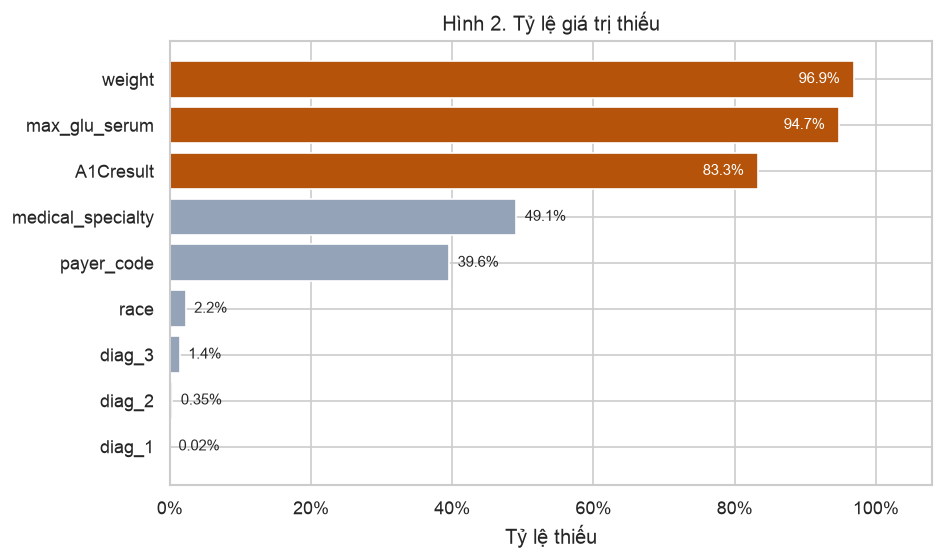

**Kết luận.** `weight` thiếu 96.9%, gần như không được ghi, nên phần sau sẽ bỏ cột này. `max_glu_serum` thiếu 94.7% và `A1Cresult` thiếu 83.3%. Hai cột này là mã kết quả xét nghiệm (Norm, >200, >300 hoặc Norm, >7, >8), không phải số liên tục. Phần sau giữ chúng và thêm mức 'không xét nghiệm', không điền trung bình. `medical_specialty`, `payer_code`, `race` và các cột `diag_*` cũng có thiếu, nhưng cách điền sẽ để ở phần xử lý sau.

In [4]:
missing_rate = df.isna().mean().sort_values(ascending=False)
missing_rate = missing_rate[missing_rate > 0]
highlight = {"weight", "max_glu_serum", "A1Cresult"}

fig, ax = plt.subplots(figsize=(8, 4.8))
plot_rate = missing_rate.sort_values(ascending=True)
colors = ["#b45309" if column in highlight else "#94a3b8" for column in plot_rate.index]
ax.barh(plot_rate.index, plot_rate.to_numpy(), color=colors)
for y_pos, rate in enumerate(plot_rate.to_numpy()):
    label = f"{rate:.1%}" if rate >= 0.01 else f"{rate:.2%}"
    if rate >= 0.75:
        ax.text(rate - 0.02, y_pos, label, va="center", ha="right", color="white", fontsize=9)
    else:
        ax.text(rate + 0.012, y_pos, label, va="center", ha="left", fontsize=9)
ax.set_xlim(0, 1.08)
ax.set_xlabel("Tỷ lệ thiếu")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda value, _pos: f"{value:.0%}"))
ax.set_title("Hình 2. Tỷ lệ giá trị thiếu")
fig.tight_layout()
plt.show()

weight_rate = float(missing_rate["weight"])
glucose_rate = float(missing_rate["max_glu_serum"])
a1c_rate = float(missing_rate["A1Cresult"])
display(Markdown(
    f"**Kết luận.** `weight` thiếu {weight_rate:.1%}, gần như không được ghi, nên phần sau sẽ bỏ cột này. "
    f"`max_glu_serum` thiếu {glucose_rate:.1%} và `A1Cresult` thiếu {a1c_rate:.1%}. "
    "Hai cột này là mã kết quả xét nghiệm (Norm, >200, >300 hoặc Norm, >7, >8), không phải số liên tục. "
    "Phần sau giữ chúng và thêm mức 'không xét nghiệm', không điền trung bình. "
    "`medical_specialty`, `payer_code`, `race` và các cột `diag_*` cũng có thiếu, nhưng cách điền sẽ để ở phần xử lý sau."
))


## 4. Cân bằng nhãn và bệnh nhân lặp

Nhãn gốc có ba mức. Cùng một `patient_nbr` có thể xuất hiện nhiều lần: nếu chia train, validation và test theo từng dòng, các lần nhập viện của một bệnh nhân sẽ lọt sang nhiều tập.


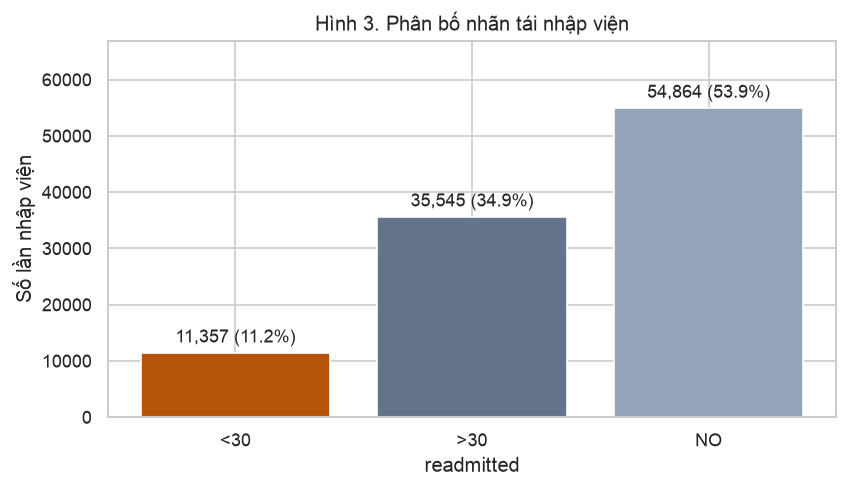

**Kết luận.** Nhãn `<30` chỉ có 11,357 / 101,766 lần nhập viện (11.2%). Khi gộp `>30` và `NO` thành không tái nhập viện sớm, bài toán nhị phân bị mất cân bằng. Phần mô hình sau cần một chỉ số khác accuracy, ví dụ recall hoặc F1 của lớp `<30`.

In [5]:
label_order = ["<30", ">30", "NO"]
label_counts = df[TARGET_COL].value_counts().reindex(label_order)
label_share = label_counts.to_numpy() / label_counts.sum()
label_colors = ["#b45309", "#64748b", "#94a3b8"]

fig, ax = plt.subplots(figsize=(7.2, 4.2))
ax.bar(label_order, label_counts.to_numpy(), color=label_colors)
for index, (count, share) in enumerate(zip(label_counts.to_numpy(), label_share)):
    ax.text(index, count + 1200, f"{int(count):,} ({share:.1%})", ha="center", va="bottom")
ax.set_ylim(0, label_counts.max() * 1.22)
ax.set_xlabel("readmitted")
ax.set_ylabel("Số lần nhập viện")
ax.set_title("Hình 3. Phân bố nhãn tái nhập viện")
fig.tight_layout()
plt.show()

early_count = int(label_counts["<30"])
early_share = float(label_share[0])
assert early_count == 11357
display(Markdown(
    f"**Kết luận.** Nhãn `<30` chỉ có {early_count:,} / {len(df):,} lần nhập viện ({early_share:.1%}). "
    "Khi gộp `>30` và `NO` thành không tái nhập viện sớm, bài toán nhị phân bị mất cân bằng. "
    "Phần mô hình sau cần một chỉ số khác accuracy, ví dụ recall hoặc F1 của lớp `<30`."
))


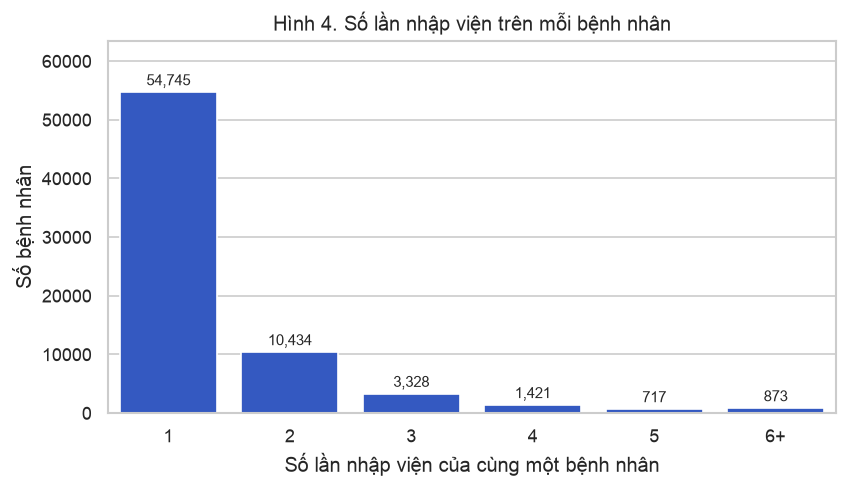

**Kết luận.** Có 71,518 bệnh nhân cho 101,766 lần nhập viện. 16,773 bệnh nhân có hơn một lần nhập viện, bệnh nhân cao nhất có 40 lần. Những bệnh nhân này chiếm 46.2% số dòng. Phần sau phải chia train, validation và test theo `patient_nbr`, không chia ngẫu nhiên theo từng dòng, để cùng một bệnh nhân không xuất hiện ở nhiều tập.

In [6]:
encounters_per_patient = df.groupby("patient_nbr").size()
n_patients = int(encounters_per_patient.shape[0])
n_repeat = int(np.sum(encounters_per_patient.to_numpy() > 1))
max_encounters = int(encounters_per_patient.max())
repeat_patients = encounters_per_patient[encounters_per_patient > 1].index
encounter_share = float(np.mean(df["patient_nbr"].isin(repeat_patients).to_numpy()))

clipped = encounters_per_patient.clip(upper=6)
bin_labels = {1: "1", 2: "2", 3: "3", 4: "4", 5: "5", 6: "6+"}
bin_order = ["1", "2", "3", "4", "5", "6+"]
binned_counts = clipped.map(bin_labels).value_counts().reindex(bin_order)

fig, ax = plt.subplots(figsize=(7.2, 4.2))
sns.barplot(x=bin_order, y=binned_counts.to_numpy(), ax=ax, color="#1d4ed8")
for index, count in enumerate(binned_counts.to_numpy()):
    ax.text(index, count + 600, f"{int(count):,}", ha="center", va="bottom", fontsize=9)
ax.set_ylim(0, binned_counts.max() * 1.16)
ax.set_xlabel("Số lần nhập viện của cùng một bệnh nhân")
ax.set_ylabel("Số bệnh nhân")
ax.set_title("Hình 4. Số lần nhập viện trên mỗi bệnh nhân")
fig.tight_layout()
plt.show()

assert n_patients == 71518
assert n_repeat == 16773
assert max_encounters == 40
display(Markdown(
    f"**Kết luận.** Có {n_patients:,} bệnh nhân cho {len(df):,} lần nhập viện. "
    f"{n_repeat:,} bệnh nhân có hơn một lần nhập viện, bệnh nhân cao nhất có {max_encounters} lần. "
    f"Những bệnh nhân này chiếm {encounter_share:.1%} số dòng. "
    "Phần sau phải chia train, validation và test theo `patient_nbr`, không chia ngẫu nhiên theo từng dòng, "
    "để cùng một bệnh nhân không xuất hiện ở nhiều tập."
))


## Phần sau

Checkpoint này dừng sau tổng quan, missing và cân bằng nhãn. Các phần chưa làm:

- Phân phối từng cột numerical và categorical.
- Ma trận tương quan.
- Xử lý outlier, gồm các cột số lần khám đang lệch mạnh (`number_emergency` tối đa 76, `number_outpatient` tối đa 42).
- So sánh nhãn với 2–3 đặc trưng.
- Bỏ `weight`; thêm mức "không xét nghiệm" cho `max_glu_serum` và `A1Cresult`; xử lý các cột thiếu còn lại.
- Encoding cột categorical và scaling cột numerical.
- Chia train, validation và test theo `patient_nbr`.
- Huấn luyện và so sánh mô hình Scikit-learn, với chỉ số phù hợp lớp `<30`.
